# Active Subspaces for Shape Optimization

__Trent Lukaczyk__, __Francisco Palacios__, and __Juan J. Alonso__, Stanford University

__Paul G. Constantine__, Colorado School of Mines

__Ryan Howard__, Colorado School of Mines (2016 notebook)

<br>

In this notebook, we summarize the active subspace analysis of the ONERA-M6 wing presented in [[1]][R1] and repeat it on the data set of that paper: the lift and drag coefficients of 297 wing designs and their gradients. The notebook uses the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later. It runs in Python 3 with numpy and matplotlib (see the repository's `requirements.txt`) and takes a few seconds.

The book [[3]][R3] (§5.3.2) also studies the ONERA-M6 wing, but with a different data set: 60 FFD parameters, 248 runs and no gradients. Those data are not in this repository, so the book's numbers for the wing do not match the ones below.

### Introduction

The field of shape design is concerned with improving aircraft performance by altering its physical shape. Realistic shape models have dozens to hundreds of parameters, characterizing as many aspects of the shape as possible, because it is not usually known beforehand which aspects of the shape will be important. This high dimensionality drastically increases the computational cost of finding optima and increases the likelihood of finding local (rather than global) solutions. Local optimizers can be efficient, but tend to return local minima; global optimizers require many function evaluations, especially in high dimensions; and many surrogate models require additional overhead and complexity as dimensionality increases. We address these issues with a dimension reduction technique known as _active subspaces_.

The active subspace methodology identifies important directions in the input space (the active subspace) along which a quantity of interest changes more, on average, than in the orthogonal directions (the inactive subspace). If there is a tight trend of the output in the active subspace, this low-dimensional structure can be used to identify global trends in the output, visualize the data (if the active subspace is of dimension 1 or 2), and perform optimization much more efficiently in this space.

### ONERA M6 Design

In this study, we are interested in the coefficients of lift ($C_L$) and drag ($C_D$) of the ONERA-M6 transonic wing in inviscid (Euler) flow at free-stream Mach number 0.8395 and angle of attack 3.06° ([[1]][R1], §II). The wing's shape is determined by 50 free-form deformation (FFD) parameters, all in the range $[-0.05, 0.05]$: a box enclosing the wing is parameterized as a Bézier solid, and its control points are the design variables, so moving them deforms the box and the wing surface inside it. Which control points, and in which directions, the parameters `x01`–`x50` move is not recorded with the data or in [[1]][R1]. An example of this kind of deformation is shown below.

<div id="image-table">
    <table>
        <tr>
            <td style="padding:5px">
                <img src="baseline_ffdbox_original.png" style="width:300px;height:265px;">
              </td>
            <td style="padding:5px">
                <img src="baseline_ffdbox_deformed.png" style="width:300px;height:265px;">
             </td>
        </tr>
    </table>
</div>

The shape is passed to the Euler solver of the [SU2](https://su2code.github.io/) suite, which computes $C_L$ and $C_D$; the SU2 adjoint solver computes their gradients with respect to the physical FFD parameters. An example of pressure contours produced by SU2 is presented below; for its typical solution, [[1]][R1] (Fig. 1) gives $C_L = 0.2864$ and $C_D = 0.0118$.

<img src="baseline_surface_flow.png" style="width:300px;height:265px;">

[[1]][R1] (§IV) samples the parameters with a 300-point Latin hypercube design. The data file has 297 of those runs; which 3 are missing, and why, is not recorded (see `DATA.md`). The data are stored SU2 output: the runs cannot be repeated from this repository.

### Active Subspaces

Consider a scalar function $f$ ($C_L$ or $C_D$ in our case) of an $m$-dimensional vector $\mathbf x$ (the 50 FFD parameters in our case), where $\mathbf x$ is normalized to be in the hypercube $[-1, 1]^m$, with gradient $\nabla f(\mathbf x)$. Let $\rho(\mathbf x)$ be a uniform probability density on $\mathbf x$ in $[-1, 1]^m$. Active subspace analysis is based on the matrix
$$
\mathbf C = \int\nabla f(\mathbf x)\nabla f(\mathbf x)^T \rho(\mathbf x)\ d\mathbf x.
$$
This can't be computed analytically in practice, so we use Monte Carlo approximation: with $\{\mathbf x_i\}_{i=1}^M$ drawn from $\rho$,
$$
\mathbf C \approx \frac{1}{M}\sum_{i=1}^M\nabla f(\mathbf x_i)\nabla f(\mathbf x_i)^T.
$$
For the ONERA-M6 wing, the gradients come from the SU2 adjoint solver, which is much less expensive than finite differences.

Since $\mathbf C$ is positive semidefinite, it has an eigendecomposition: $\mathbf C = \mathbf W\mathbf\Lambda\mathbf W^T$, where $\mathbf W$ contains $\mathbf C$'s eigenvectors in its columns and $\mathbf\Lambda$ is a diagonal matrix of eigenvalues (assume the eigenvalues/vectors are in descending order). We choose the dimension of our reduced space, $n$, and partition $\mathbf W$ and $\mathbf\Lambda$:

$$
\mathbf W = \left[\begin{matrix}\mathbf U & \mathbf V\end{matrix}\right],\ \mathbf\Lambda = \left[\begin{matrix}\mathbf \Lambda_1 & \\ & \mathbf \Lambda_2\end{matrix}\right],
$$

where $\mathbf U$ contains the first $n$ eigenvectors and $\mathbf\Lambda_1$ has the first $n$ eigenvalues (this is valid so long as $\lambda_n > \lambda_{n+1}$). $\mathbf U$ is a basis in the active subspace (we follow the notation of [[1]][R1]; the code calls it `W1`), and the active variable $\mathbf y$ is found as $\mathbf y = \mathbf U^T\mathbf x$. We can approximate $f$ in the low-dimensional active subspace as:

$$
f(\mathbf x) \approx g(\mathbf U^T\mathbf x) = g(\mathbf y) \approx \mathcal{R}(\mathbf y),
$$

where $\mathcal{R}(\mathbf y)$ is a response surface trained with the points $\{(\mathbf y_i,\ f(\mathbf x_i))\}$.

### References

[[1]][R1] T.W. Lukaczyk, F. Palacios, J.J. Alonso, and P.G. Constantine. _Active Subspaces for Shape Optimization_. 10th AIAA Multidisciplinary Design Optimization Conference, AIAA SciTech, National Harbor, MD, January 2014. AIAA 2014-1171. doi:10.2514/6.2014-1171

[[2]][R2] P.G. Constantine, E. Dow, and Q. Wang. _Active subspace methods in theory and practice: applications to kriging surfaces_. SIAM J. Sci. Comput., 36(4), A1500–A1524, 2014. doi:10.1137/130916138

[[3]][R3] P.G. Constantine. _Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies_. SIAM, 2015. doi:10.1137/1.9781611973860

[R1]: https://doi.org/10.2514/6.2014-1171
[R2]: https://doi.org/10.1137/130916138
[R3]: https://doi.org/10.1137/1.9781611973860

### Acknowledgments

This material is based upon work supported by the U.S. Department of Energy Office of Science, Office of Advanced Scientific Computing Research, Applied Mathematics program under Award Number DE-SC-0011077.

<br>

We'll now code up the analysis using the [active_subspaces](https://github.com/paulcon/active_subspaces) library.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac

t_start = time.perf_counter()
rng = np.random.default_rng(2014)        # the only source of randomness (the bootstrap) in this notebook

Import the data set. Distinguish inputs, outputs, and gradients. The file `ONERA-M6.txt` has a header line and one row per SU2 run: the run number, the 50 parameters `x01`–`x50`, the lift and drag coefficients, and their gradients `dlift01`–`dlift50` and `ddrag01`–`ddrag50`. The inputs are in physical units ($[-0.05, 0.05]$), and so are the gradients: they are derivatives with respect to the physical parameters, not the normalized ones.

We also check the sampling. In a Latin hypercube design of 300 points, each parameter's range is cut into 300 equal strata and each stratum holds exactly one point. If the file holds 297 runs of such a design, each column should have values in 297 distinct strata.

In [2]:
with open('ONERA-M6.txt') as fh:
    header = fh.readline().strip().split(',')
data = np.loadtxt('ONERA-M6.txt', delimiter=',', skiprows=1)

m = 50                                   # number of input parameters
run = data[:, 0].astype(int)
X = data[:, 1:m+1]                       # inputs, physical units
f = {'Lift': data[:, m+1], 'Drag': data[:, m+2]}
G = {'Lift': data[:, m+3:2*m+3],         # gradients with respect to the PHYSICAL inputs
     'Drag': data[:, 2*m+3:]}
names = header[1:m+1]
qois = ['Lift', 'Drag']
M = len(X)
assert header[m+1:m+3] == qois and header[m+3] == 'dlift01' and header[2*m+3] == 'ddrag01' and header[-1] == 'ddrag50'

print(f'{M} runs (Run = {run.min()}..{run.max()}, consecutive: {np.array_equal(run, np.arange(1, M + 1))}), '
      f'{m} parameters, {len(np.unique(X, axis=0))} distinct input rows')
print(f'inputs in [{X.min():.5f}, {X.max():.5f}], std {X.std():.5f} (uniform on [-0.05, 0.05]: {0.05/np.sqrt(3):.5f})')
strata = np.floor((X + 0.05) / 0.1 * 300).astype(int)
counts = [len(np.unique(strata[:, j])) for j in range(m)]
print(f'occupied strata out of 300, per column: min {min(counts)}, max {max(counts)}')
for q in qois:
    print(f'{q}: {f[q].min():.4f} to {f[q].max():.4f}')

297 runs (Run = 1..297, consecutive: True), 50 parameters, 297 distinct input rows
inputs in [-0.04999, 0.05000], std 0.02886 (uniform on [-0.05, 0.05]: 0.02887)
occupied strata out of 300, per column: min 297, max 297
Lift: 0.1038 to 0.5026
Drag: 0.0036 to 0.0455


The 297 runs occupy 297 distinct strata in every column, as 297 of the 300 points of a Latin hypercube design would. Which 3 runs are missing cannot be told from this: each column has 3 empty strata, but nothing pairs them into runs. [[1]](https://doi.org/10.2514/6.2014-1171) (§IV) says the bounds $[-0.05, 0.05]$ were shrunk "until a majority of the flow evaluations would successfully converge", so the missing runs may be failed SU2 runs; that is a guess, not a record.

Next, we check that the gradients are with respect to the physical inputs. If they were with respect to the normalized inputs $\mathbf x = \boldsymbol\xi/0.05$, the slope of a least-squares linear fit of $f$ on the physical inputs $\boldsymbol\xi$ would be about 20 times the mean gradient; it is about the same.

In [3]:
A = np.hstack([np.ones((M, 1)), X])
for q in qois:
    slope = np.linalg.lstsq(A, f[q], rcond=None)[0][1:]
    g_mean = G[q].mean(axis=0)
    print(f'{q}: (linear-fit slope . mean gradient) / |mean gradient|^2 = {slope @ g_mean / (g_mean @ g_mean):.2f}, '
          f'correlation {np.corrcoef(slope, g_mean)[0, 1]:.3f}')

Lift: (linear-fit slope . mean gradient) / |mean gradient|^2 = 1.10, correlation 0.986
Drag: (linear-fit slope . mean gradient) / |mean gradient|^2 = 0.91, correlation 0.871


Compute the active subspaces. The input space is the box $[-0.05, 0.05]^{50}$ with the uniform density; `ac.active_subspace` takes the physical gradients and maps them to the normalized coordinates by the chain rule, multiplying each by the half-width 0.05.

The 2016 version of this notebook passed the physical gradients as if they were normalized ones. Its eigenvectors are the same (all 50 parameters have the same range), but its eigenvalues are $1/0.05^2 = 400$ times ours. We first check this with the 2016 computation (the eigendecomposition of $\frac 1 M\sum_i\nabla f_i\nabla f_i^T$ for the raw gradients), and then compute the subspaces with 500 bootstrap replicates, as in 2016.

Eigenvector signs are arbitrary. The 2016 package made the first component of each eigenvector positive. We keep that rule for the first two eigenvectors of drag and the second of lift (v1's own rule, largest component positive, gives the same signs here). For the first lift eigenvector we follow [[1]](https://doi.org/10.2514/6.2014-1171) instead: its Fig. 6 shows lift decreasing along the active variable, so we make $\mathbf u$ point against the mean gradient. This is the opposite sign to the 2016 notebook. The paper's drag figure (Fig. 7) is a 3-D surface whose axis directions cannot be read reliably, so drag keeps the 2016 signs.

In [4]:
space = ac.Uniform(np.full(m, -0.05), np.full(m, 0.05), names=names)
e1 = np.eye(m)[:, [0, 0]]                # reference for the 2016 sign rule: first component positive
fmt = lambda v: ', '.join(f'{x:.4e}' for x in v)

print('check against the 2016 computation')
for q in qois:
    lam16, W16 = np.linalg.eigh(G[q].T @ G[q] / M)
    lam16, W16 = lam16[::-1], W16[:, ::-1]
    s = ac.active_subspace(space=space, grads=G[q], qoi=q)
    print(f'  {q}: lambda_1, lambda_2 = {fmt(s.eigenvalues[:2])}; 2016 values = {fmt(lam16[:2])}; '
          f'ratio = {fmt(s.eigenvalues[:2] / lam16[:2])}')
    print(f'  {" " * len(q)}  1 - |w1 . w1(2016)| = {abs(1 - abs(s.W[:, 0] @ W16[:, 0])):.0e}, '
          f'1 - |w2 . w2(2016)| = {abs(1 - abs(s.W[:, 1] @ W16[:, 1])):.0e}')

sub = {q: ac.orient(ac.active_subspace(space=space, grads=G[q], nboot=500, rng=rng, qoi=q),
                    by='reference', reference=e1, columns=2)
       for q in qois}
g_lift = 0.05 * G['Lift'].mean(axis=0)    # mean lift gradient, normalized coordinates
sub['Lift'] = ac.orient(sub['Lift'], by='reference', reference=-g_lift[:, None], columns=1)

print('\neigenvalues and the eigenvalue-gap rule (EVG, the v1 default)')
for q in qois:
    lam = sub[q].eigenvalues
    ks, gaps, k_evg = ac.dimension_criterion(sub[q], rule='evg')
    k_log = ac.dimension_criterion(sub[q], rule=ac.subspaces.EVG(gap='log'))[2]
    print(f'  {q}: lambda_1..5 = {fmt(lam[:5])}')
    print(f'  {" " * len(q)}  lambda_1/lambda_2 = {lam[0] / lam[1]:.3g}, lambda_2/lambda_3 = {lam[1] / lam[2]:.3g}')
    print(f'  {" " * len(q)}  gaps lambda_k - lambda_(k+1), k = 1..3: {fmt(gaps[:3])}; '
          f'first gap / second gap = {gaps[0] / gaps[1]:.3g}')
    print(f'  {" " * len(q)}  EVG chooses n = {k_evg} (with log gaps: n = {k_log})')
    print(f'  {" " * len(q)}  mean bootstrap subspace distance, n = 1..3: '
          + ', '.join(f'{v:.3f}' for v in sub[q].bootstrap_distances.mean(axis=0)[:3]))

check against the 2016 computation
  Lift: lambda_1, lambda_2 = 1.5905e-02, 1.3808e-04; 2016 values = 6.3621e+00, 5.5233e-02; ratio = 2.5000e-03, 2.5000e-03
        1 - |w1 . w1(2016)| = 4e-16, 1 - |w2 . w2(2016)| = 7e-16
  Drag: lambda_1, lambda_2 = 1.1601e-04, 6.3601e-05; 2016 values = 4.6405e-02, 2.5440e-02; ratio = 2.5000e-03, 2.5000e-03
        1 - |w1 . w1(2016)| = 2e-16, 1 - |w2 . w2(2016)| = 1e-15



eigenvalues and the eigenvalue-gap rule (EVG, the v1 default)
  Lift: lambda_1..5 = 1.5905e-02, 1.3808e-04, 4.3516e-05, 2.9978e-05, 1.9049e-05
        lambda_1/lambda_2 = 115, lambda_2/lambda_3 = 3.17
        gaps lambda_k - lambda_(k+1), k = 1..3: 1.5767e-02, 9.4565e-05, 1.3538e-05; first gap / second gap = 167
        EVG chooses n = 1 (with log gaps: n = 1)
        mean bootstrap subspace distance, n = 1..3: 0.007, 0.087, 0.296
  Drag: lambda_1..5 = 1.1601e-04, 6.3601e-05, 1.3936e-05, 4.5760e-06, 1.7097e-06
        lambda_1/lambda_2 = 1.82, lambda_2/lambda_3 = 4.56
        gaps lambda_k - lambda_(k+1), k = 1..3: 5.2411e-05, 4.9665e-05, 9.3603e-06; first gap / second gap = 1.06
        EVG chooses n = 1 (with log gaps: n = 49)
        mean bootstrap subspace distance, n = 1..3: 0.082, 0.052, 0.070


For lift, the eigenvalue-gap rule (EVG) chooses $n = 1$, and we keep it. For drag it also chooses $n = 1$, but only just: the gap $\lambda_1 - \lambda_2$ is only 1.06 times $\lambda_2 - \lambda_3$. Relative to their size, $\lambda_1$ and $\lambda_2$ are close ($\lambda_1/\lambda_2 \approx 1.8$) and both are well separated from $\lambda_3$ ($\lambda_2/\lambda_3 \approx 4.6$), and the bootstrap subspace distance is smaller for $n = 2$ than for $n = 1$. We therefore set $n = 2$ for drag explicitly. (The log-gap variant of the rule picks $n = 49$ for drag, because the smallest eigenvalues fall off steeply, so it does not help here.)

In [5]:
sub['Drag'] = ac.with_dimension(sub['Drag'], 2)
for q in qois:
    print(f'{q}: n = {sub[q].n}')

Lift: n = 1
Drag: n = 2


Now we plot the eigenvalues for both lift and drag, with the 95% bootstrap ranges as bands.

Lift: lambda_k / sum(lambda), k = 1..3: 0.983, 0.00853, 0.00269; [1] Fig. 4, read off: 1, 0.008, 0.0025
Drag: lambda_k / sum(lambda), k = 1..3: 0.571, 0.313, 0.0686; [1] Fig. 4, read off: 0.6, 0.3, 0.08


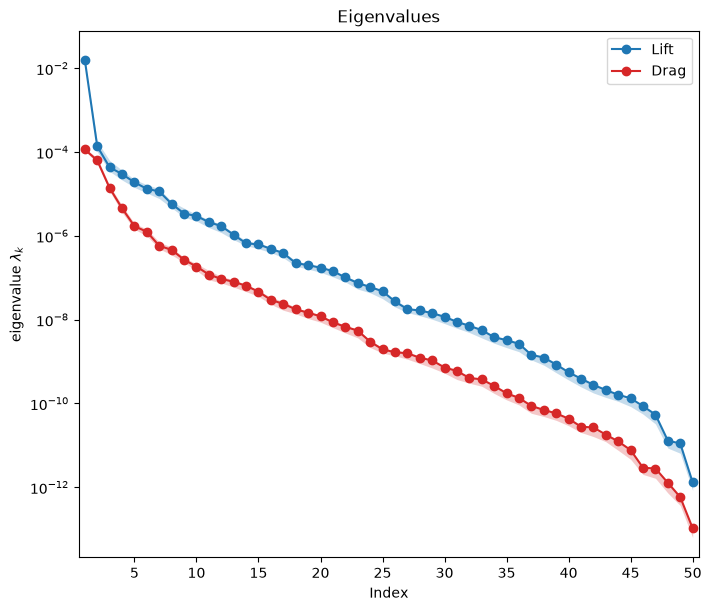

In [6]:
fig, ax = plt.subplots(figsize=(7, 6), layout='constrained')
for q, color in zip(qois, ['C0', 'C3']):
    ac.plotting.plot_eigenvalues(sub[q], mark_dimension=False, ax=ax,
                                 line_kw={'color': color, 'label': q}, band_kw={'color': color})
lam_all = np.concatenate([sub[q].eigenvalues for q in qois])
ax.set_ylim(lam_all.min() / 5, lam_all.max() * 5)
ax.set_xlabel('Index')
ax.set_title('Eigenvalues')
ax.legend()

fig4 = {'Lift': [1, 0.008, 0.0025], 'Drag': [0.6, 0.3, 0.08]}   # read off the log-scale plot of [1] Fig. 4
for q in qois:
    lam = sub[q].eigenvalues
    print(f'{q}: lambda_k / sum(lambda), k = 1..3: ' + ', '.join(f'{v:.3g}' for v in lam[:3] / lam.sum())
          + '; [1] Fig. 4, read off: ' + ', '.join(f'{v:.2g}' for v in fig4[q]))

Large gaps in eigenvalue magnitude indicate the likely presence of an active subspace. The gap between the first and second eigenvalues for lift ($\lambda_1/\lambda_2 \approx 115$) indicates a 1-dimensional active subspace; a 2-dimensional active subspace looks more likely for drag.

The curves have the shape of [[1]](https://doi.org/10.2514/6.2014-1171) Fig. 4. That figure's values match eigenvalues divided by their sum (printed above beside values read off the figure), but the paper does not state the scaling; it also used all 300 runs. [[1]](https://doi.org/10.2514/6.2014-1171) keeps one dimension for lift. For drag it chooses **five** dimensions, from the decay of the eigenvalues and of a surrogate's training error (its Fig. 5), and restricts to two for visualization (Fig. 7).

<br>

Next we examine how well a response surface in the first $n$ active variables predicts each output, for $n$ up to 10. For each $n$ we fit a radial basis function (RBF) surrogate with a quadratic polynomial mean and compute its leave-one-out $R^2$: each run is predicted by the surrogate fitted to the other 296. This study is this notebook's own; [[1]](https://doi.org/10.2514/6.2014-1171) reports training errors of Gaussian process surrogates instead.

                             n      1      2      3      4      5      6      7      8      9     10
       Lift, leave-one-out R^2  0.980  0.983  0.985  0.986  0.986  0.987  0.987  0.987  0.987  0.987
        2016 figure, in-sample 0.9987 0.9989 0.9990 0.9991 0.9991 0.9992 0.9993 0.9994 0.9994 0.9995
       Drag, leave-one-out R^2  0.703  0.884  0.932  0.940  0.945  0.951  0.952  0.955  0.955  0.968
        2016 figure, in-sample 0.9644 0.9864 0.9925 0.9937 0.9943 0.9954 0.9959 0.9962 0.9967 0.9976


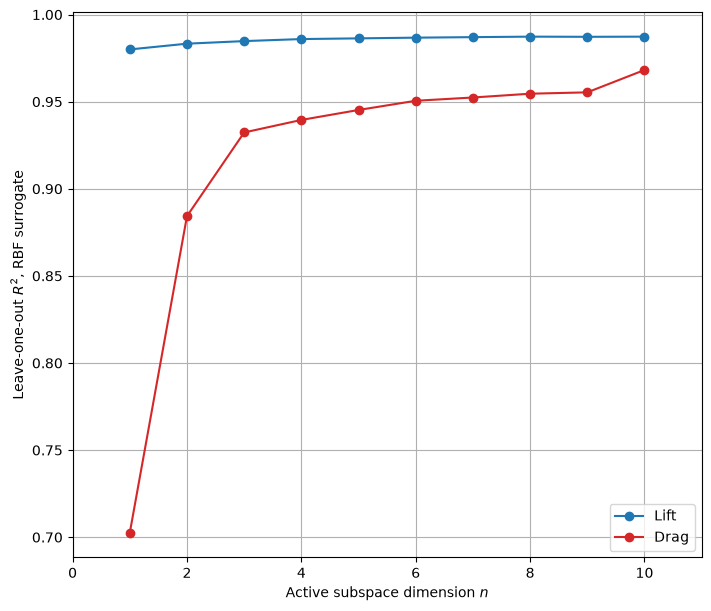

In [7]:
n_max = 10
ns = np.arange(1, n_max + 1)
r2 = {q: np.array([ac.fit_surrogate(X=X, f=f[q], subspace=ac.with_dimension(sub[q], n), kind='rbf', degree=2).loo_r_squared
                   for n in ns])
      for q in qois}
# in-sample R^2 of the 2016 RBF surrogates, read off the 2016 notebook's figure (about +-0.0003)
r2_2016 = {'Lift': [0.9987, 0.9989, 0.9990, 0.9991, 0.9991, 0.9992, 0.9993, 0.9994, 0.9994, 0.9995],
           'Drag': [0.9644, 0.9864, 0.9925, 0.9937, 0.9943, 0.9954, 0.9959, 0.9962, 0.9967, 0.9976]}

print(f'{"n":>30}' + ''.join(f'{n:>7d}' for n in ns))
for q in qois:
    print(f'{q + ", leave-one-out R^2":>30}' + ''.join(f'{v:7.3f}' for v in r2[q]))
    print(f'{"2016 figure, in-sample":>30}' + ''.join(f'{v:7.4f}' for v in r2_2016[q]))

fig, ax = plt.subplots(figsize=(7, 6), layout='constrained')
for q, color in zip(qois, ['C0', 'C3']):
    ax.plot(ns, r2[q], 'o-', color=color, label=q)
ax.set_xlim(0, n_max + 1)
ax.grid(True)
ax.set_xlabel('Active subspace dimension $n$')
ax.set_ylabel('Leave-one-out $R^2$, RBF surrogate')
ax.legend(loc='lower right');

The leave-one-out $R^2$ for lift starts high, 0.980 with one active variable, and gains little from more (0.987 at $n = 10$). For drag it starts at 0.703 with one active variable and rises to 0.884 with two, 0.932 with three and 0.945 with five, then gains slowly (0.968 at $n = 10$). These facts support our reading of the eigenvalues: the active subspace for lift is strong at 1 dimension, while drag needs at least 2 dimensions and keeps improving up to about 5, in line with the paper's choice.

The 2016 version of this notebook plotted in-sample $R^2$ (the fit at the training points) of a differently fitted RBF surrogate (printed above, read off its figure); for drag it started at about 0.964. In-sample $R^2$ overstates how well a surrogate predicts new designs, so the leave-one-out values are lower, but the conclusion is the same and clearer.

<br>

We can visualize the data in the 1- or 2-dimensional subspaces with sufficient summary plots (plots of output vs. active variable values):

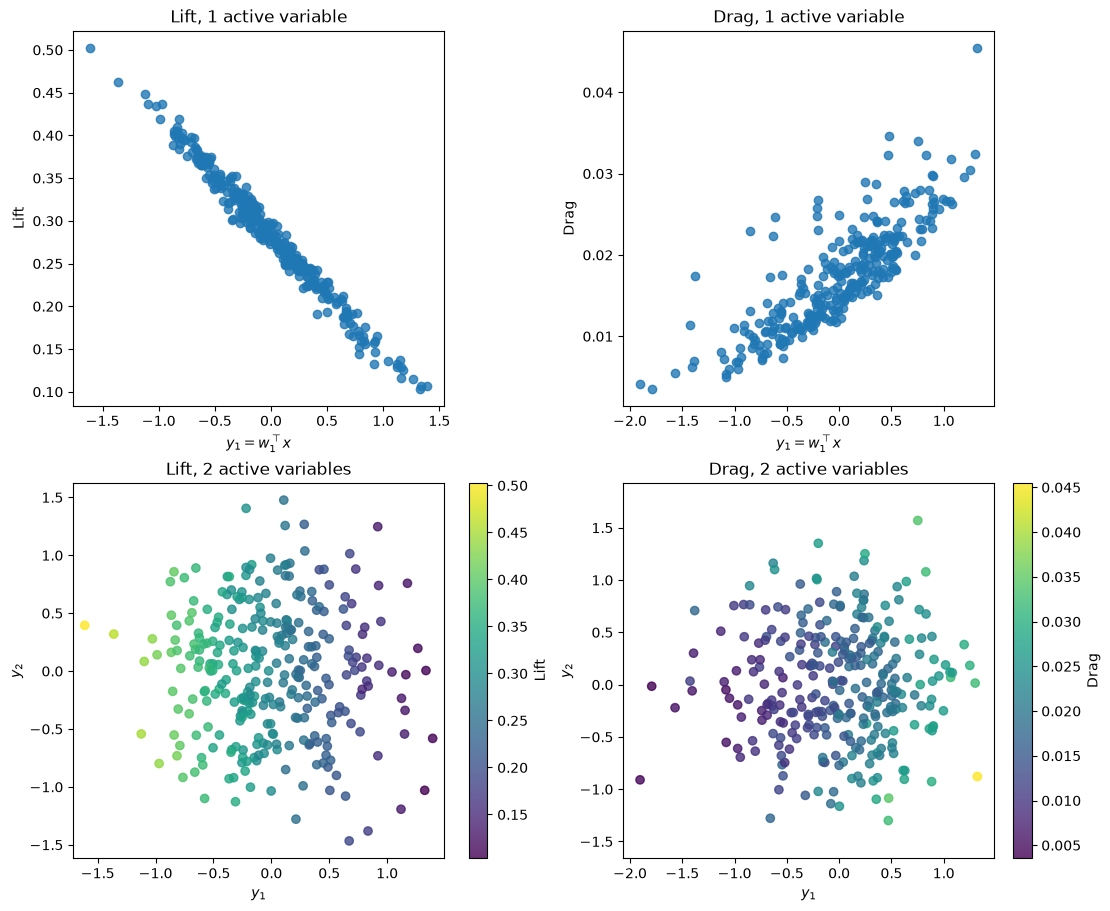

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9), layout='constrained')
for j, q in enumerate(qois):
    for i, dims in enumerate((1, 2)):
        ac.plotting.plot_sufficient_summary(sub[q], X=X, f=f[q], dims=dims, ax=axes[i, j])
        axes[i, j].set_title(f'{q}, {dims} active variable{"s" if dims == 2 else ""}')

The strong trend is apparent for lift, as the $R^2$ value would lead us to suspect. Lift decreases along the active variable, as in [[1]](https://doi.org/10.2514/6.2014-1171) Fig. 6; that figure's horizontal axis is $\mathbf u^T\boldsymbol\xi$ for the physical inputs $\boldsymbol\xi = 0.05\,\mathbf x$, so its scale is 0.05 times ours. There is a significant 1-dimensional trend for drag, but with more spread around it; in the 2-dimensional plot, drag changes along $y_2$ as well as $y_1$, as the second eigenvalue and the rise in $R^2$ from one to two active variables suggest.

<br>

Since our input parameters are bounded, it is natural to wonder what the bounds of our active variables are. The bounds are defined by a projection of the $m$-dimensional hypercube down to the $n$-dimensional subspace. For 1 dimension, it is simply an interval whose endpoints are $\pm |\mathbf u|^T\mathbf 1$, where $\mathbf u$ is the active subspace basis, $|\cdot|$ denotes componentwise absolute value, and $\mathbf 1$ is a column vector of 1's. In higher dimensions, the projection is a zonotope, a convex polytope that can have many vertices. We'll now show 2-dimensional summary plots with the boundaries as well.

Lift, n = 1: active domain [-6.0391, 6.0391], |u|^T 1 = 6.0391
Lift, n = 2: zonotope with 100 vertices
Drag, n = 2: zonotope with 100 vertices


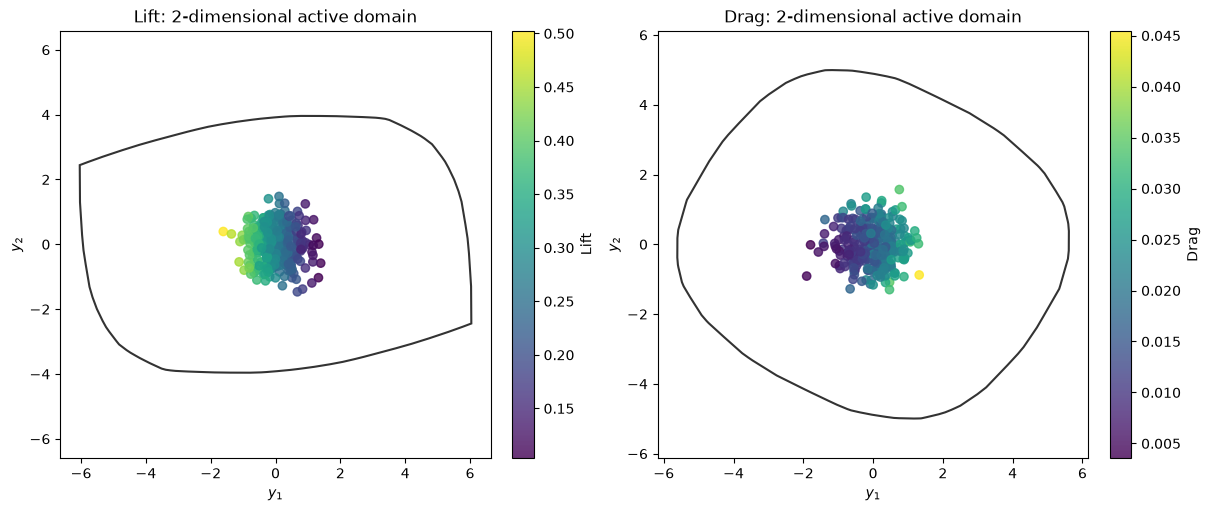

In [9]:
dom1 = ac.active_domain(ac.with_dimension(sub['Lift'], 1))
print(f'Lift, n = 1: active domain [{dom1.vertices.min():.4f}, {dom1.vertices.max():.4f}], '
      f'|u|^T 1 = {np.abs(sub["Lift"].W[:, 0]).sum():.4f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
for j, q in enumerate(qois):
    s2 = ac.with_dimension(sub[q], 2)
    dom = ac.active_domain(s2)
    ac.plotting.plot_sufficient_summary(s2, X=X, f=f[q], domain=dom, ax=axes[j])
    axes[j].set_title(f'{q}: 2-dimensional active domain')
    axes[j].set_aspect('equal')
    print(f'{q}, n = 2: zonotope with {dom.n_vertices} vertices')

The samples fill only the middle of each zonotope. That is expected: an active variable is a weighted sum of 50 independent inputs, so it concentrates near zero, and the vertices of the zonotope are reached only at corners of the hypercube.

### Utilizing Active Subspaces

A possible use of active subspaces for the ONERA-M6 wing is constrained optimization: minimizing drag keeping lift above some threshold. [[1]][R1] (eq. 1) minimizes $C_D$ subject to $C_L \geq 0.2864$. We would do this by finding the range of lift's active variable that keeps lift above the threshold, inverting the active variable map to the input space to find the region of the input space that satisfies our lift constraint, and finding the subset of drag's valid active variable domain corresponding to this region. When we have this region, we can use a response surface to estimate the minimum drag achievable, and map the minimizer to the input space as our solution. We could also collect more samples from the region of drag's active variable domain satisfying the lift constraint to construct a more robust response surface or use our estimated minimizer as a starting point for an optimization algorithm in the full input space, ensuring we start close to the true global minimizer. [[1]][R1] discusses these kinds of calculations in some detail and presents the specific results for the ONERA-M6, with a linear model of lift in one active variable and a quadratic model of drag in five. [[2]][R2] and [[3]][R3] discuss in detail some other possible uses for active subspaces, such as integration, inversion, and response surface construction.

[R1]: https://doi.org/10.2514/6.2014-1171
[R2]: https://doi.org/10.1137/130916138
[R3]: https://doi.org/10.1137/1.9781611973860

In [10]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 24.7 s
